In [3]:
# Cell 1 — Imports and configuration
# Run this cell first. Change experiment settings only in this cell.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
N_TRAIN = 500
N_VAL = 200
N_TEST = 1000
P = 10
NOISE_STD = 1.0
CONTAMINATION_RATIO = 0.10
CONTAMINATION_MAGNITUDE = 5.0
CONTAMINATION_TYPE = "response"  # "response" or "cellwise"

# Benchmark grid. The single experiment above is shown before this grid runs.
BENCHMARK_DIMENSIONS = [5, 10, 20, 40]
BENCHMARK_RATIOS = [0.00, 0.05, 0.10, 0.20, 0.30]
BENCHMARK_MAGNITUDES = [2.0, 5.0, 10.0]
BENCHMARK_TYPES = ["response", "cellwise"]
BENCHMARK_REPEATS = 20

if CONTAMINATION_TYPE not in {"response", "cellwise"}:
    raise ValueError("CONTAMINATION_TYPE must be 'response' or 'cellwise'.")
if not 0.0 <= CONTAMINATION_RATIO <= 1.0:
    raise ValueError("CONTAMINATION_RATIO must be between 0 and 1.")

pd.set_option("display.precision", 3)
plt.style.use("seaborn-v0_8-whitegrid")


In [4]:
# Cell 2 — Generate true beta
# beta_true is known because this is a controlled synthetic experiment.

rng = np.random.default_rng(SEED)
beta_true = rng.normal(loc=0.0, scale=1.0, size=P)

print("beta_true:")
print(pd.Series(beta_true, index=[f"x{i + 1}" for i in range(P)], name="coefficient"))


beta_true:
x1     0.305
x2    -1.040
x3     0.750
x4     0.941
x5    -1.951
x6    -1.302
x7     0.128
x8    -0.316
x9    -0.017
x10   -0.853
Name: coefficient, dtype: float64


In [5]:
# Cell 3 — Generate clean train / validation / test sets
# Each split is independently generated. Only the training split is contaminated later.

def generate_clean_set(n_samples, beta, noise_std, generator):
    """Return X and y from y = X @ beta + Normal(0, noise_std)."""
    X = generator.normal(loc=0.0, scale=1.0, size=(n_samples, len(beta)))
    noise = generator.normal(loc=0.0, scale=noise_std, size=n_samples)
    y = X @ beta + noise
    return X, y


X_train_clean, y_train_clean = generate_clean_set(N_TRAIN, beta_true, NOISE_STD, rng)
X_val, y_val = generate_clean_set(N_VAL, beta_true, NOISE_STD, rng)
X_test, y_test = generate_clean_set(N_TEST, beta_true, NOISE_STD, rng)

print(f"X_train_clean: {X_train_clean.shape}; y_train_clean: {y_train_clean.shape}")
print(f"X_val: {X_val.shape}; y_val: {y_val.shape}")
print(f"X_test: {X_test.shape}; y_test: {y_test.shape}")


X_train_clean: (500, 10); y_train_clean: (500,)
X_val: (200, 10); y_val: (200,)
X_test: (1000, 10); y_test: (1000,)


In [6]:
# Cell 4 — Inject contamination into training set only
# X_train_clean and y_train_clean are never modified in place.

def inject_contamination(X_clean, y_clean, contamination_type, ratio, magnitude, noise_std, generator):
    """Return observed training data and masks describing every changed value.

    response: a ratio of training rows receives +/- magnitude * noise_std in y.
    cellwise: a ratio of feature cells receives +/- magnitude in X; the target
    remains generated from the original clean features.
    """
    X_observed = X_clean.copy()
    y_observed = y_clean.copy()
    response_mask = np.zeros(len(y_clean), dtype=bool)
    feature_mask = np.zeros_like(X_clean, dtype=bool)

    if contamination_type == "response":
        response_mask = generator.random(len(y_clean)) < ratio
        signs = generator.choice([-1.0, 1.0], size=response_mask.sum())
        y_observed[response_mask] += signs * magnitude * noise_std
    elif contamination_type == "cellwise":
        feature_mask = generator.random(X_clean.shape) < ratio
        signs = generator.choice([-1.0, 1.0], size=feature_mask.sum())
        X_observed[feature_mask] += signs * magnitude
    else:
        raise ValueError("contamination_type must be 'response' or 'cellwise'.")

    return X_observed, y_observed, response_mask, feature_mask


X_train_observed, y_train_observed, response_mask, feature_mask = inject_contamination(
    X_train_clean,
    y_train_clean,
    CONTAMINATION_TYPE,
    CONTAMINATION_RATIO,
    CONTAMINATION_MAGNITUDE,
    NOISE_STD,
    rng,
)

affected_rows = response_mask | feature_mask.any(axis=1)
print(f"contamination type: {CONTAMINATION_TYPE}")
print(f"affected training rows: {affected_rows.sum()} / {N_TRAIN}")
print(f"contaminated feature cells: {feature_mask.sum()} / {N_TRAIN * P}")
print("Validation and test data remain clean.")


contamination type: response
affected training rows: 53 / 500
contaminated feature cells: 0 / 5000
Validation and test data remain clean.


In [7]:
# Cell 5 — Show clean vs contaminated training samples

feature_names = [f"x{i + 1}" for i in range(P)]
sample_table = pd.DataFrame(X_train_observed, columns=feature_names)
sample_table.insert(0, "row_id", np.arange(N_TRAIN))
sample_table["y_clean"] = y_train_clean
sample_table["y_observed"] = y_train_observed
sample_table["response_contaminated"] = response_mask
sample_table["contaminated_feature_count"] = feature_mask.sum(axis=1)

clean_example_ids = np.flatnonzero(~affected_rows)[:5]
contaminated_example_ids = np.flatnonzero(affected_rows)[:5]

print("Clean training examples (observed values equal clean values):")
display(sample_table.iloc[clean_example_ids])

print("Contaminated training examples:")
display(sample_table.iloc[contaminated_example_ids])

if CONTAMINATION_TYPE == "cellwise" and len(contaminated_example_ids):
    first_id = contaminated_example_ids[0]
    changed_names = np.array(feature_names)[feature_mask[first_id]]
    print(f"row {first_id}: contaminated feature cells = {list(changed_names)}")


Clean training examples (observed values equal clean values):


,row_id,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,y_clean,y_observed,response_contaminated,contaminated_feature_count
0,0,0.879,0.778,0.066,1.127,0.468,-0.859,0.369,-0.959,0.878,-0.050,1.935,1.935,False,0
1,1,-0.185,-0.681,1.223,-0.155,-0.428,-0.352,0.532,0.365,0.413,0.431,1.025,1.025,False,0
2,2,2.142,-0.406,-0.512,-0.814,0.616,1.129,-0.114,-0.840,-0.824,0.651,-4.448,-4.448,False,0
3,3,0.743,0.543,-0.666,0.232,0.117,0.219,0.871,0.224,0.679,0.068,0.514,0.514,False,0
4,4,0.289,0.631,-1.457,-0.320,-0.470,-0.639,-0.275,1.495,-0.866,0.968,-1.181,-1.181,False,0


Contaminated training examples:


,row_id,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,y_clean,y_observed,response_contaminated,contaminated_feature_count
32,32,1.511,0.638,-0.699,-1.014,0.033,-1.217,-0.671,0.312,1.155,0.609,-0.507,4.493,True,0
47,47,0.223,1.433,0.092,0.581,-0.057,-0.170,-0.779,0.430,-0.852,0.666,-1.654,3.346,True,0
52,52,-0.362,-0.941,-0.449,0.452,-1.566,0.637,-0.539,1.148,-2.394,-0.787,2.485,7.485,True,0
61,61,-0.441,0.032,0.269,-0.620,0.471,-0.533,-0.412,1.363,-1.041,-2.413,0.770,-4.230,True,0
72,72,0.448,0.058,0.549,-0.188,0.278,0.158,0.778,0.807,-1.620,-2.247,1.451,6.451,True,0


In [8]:
# Cell 6 — Train ordinary least-squares linear regression on observed training data
# The intercept is fitted by adding a leading column of ones.

def add_intercept(X):
    return np.column_stack([np.ones(len(X)), X])


X_train_design = add_intercept(X_train_observed)
normal_matrix = X_train_design.T @ X_train_design
normal_target = X_train_design.T @ y_train_observed
theta_hat = np.linalg.solve(normal_matrix, normal_target)

intercept_hat = theta_hat[0]
beta_hat = theta_hat[1:]
y_train_pred = add_intercept(X_train_observed) @ theta_hat
train_mse = np.mean((y_train_observed - y_train_pred) ** 2)

print(f"intercept_hat = {intercept_hat:.3f}")
print(f"training MSE on observed targets = {train_mse:.3f}")
display(
    pd.DataFrame(
        {"beta_true": beta_true, "beta_hat": beta_hat, "difference": beta_hat - beta_true},
        index=feature_names,
    )
)


intercept_hat = 0.057
training MSE on observed targets = 3.478


,beta_true,beta_hat,difference
x1,0.305,0.434,0.129
x2,-1.040,-0.838,0.202
x3,0.750,0.810,0.060
x4,0.941,1.052,0.111
x5,-1.951,-1.974,-0.023
x6,-1.302,-1.218,0.084
x7,0.128,0.230,0.102
x8,-0.316,-0.365,-0.048
x9,-0.017,-0.139,-0.122
x10,-0.853,-0.916,-0.063


In [9]:
# Cell 7 — Evaluate on clean validation/test data

def regression_metrics(X, y, theta, beta_reference):
    predictions = add_intercept(X) @ theta
    residuals = y - predictions
    mse = np.mean(residuals**2)
    mae = np.mean(np.abs(residuals))
    r2 = 1.0 - np.sum(residuals**2) / np.sum((y - y.mean()) ** 2)
    parameter_error = np.linalg.norm(theta[1:] - beta_reference)
    relative_parameter_error = parameter_error / np.linalg.norm(beta_reference)
    return {
        "MSE": mse,
        "MAE": mae,
        "R2": r2,
        "parameter_L2_error": parameter_error,
        "relative_parameter_error": relative_parameter_error,
    }


validation_metrics = regression_metrics(X_val, y_val, theta_hat, beta_true)
test_metrics = regression_metrics(X_test, y_test, theta_hat, beta_true)
evaluation_table = pd.DataFrame([validation_metrics, test_metrics], index=["clean validation", "clean test"])
display(evaluation_table)


,MSE,MAE,R2,parameter_L2_error,relative_parameter_error
clean validation,1.067,0.809,0.892,0.336,0.112
clean test,1.072,0.842,0.889,0.336,0.112


In [10]:
# Cell 8 — Run benchmark over predefined parameter grids
# This helper repeats the already-shown single-experiment workflow. It does not
# replace the visible top-level workflow in cells 2–7.

def run_benchmark_experiment(p, ratio, magnitude, contamination_type, seed):
    generator = np.random.default_rng(seed)
    beta = generator.normal(0.0, 1.0, size=p)
    X_train, y_train = generate_clean_set(N_TRAIN, beta, NOISE_STD, generator)
    X_validation, y_validation = generate_clean_set(N_VAL, beta, NOISE_STD, generator)
    X_testing, y_testing = generate_clean_set(N_TEST, beta, NOISE_STD, generator)
    X_observed, y_observed, _, _ = inject_contamination(
        X_train, y_train, contamination_type, ratio, magnitude, NOISE_STD, generator
    )
    X_design = add_intercept(X_observed)
    theta = np.linalg.solve(X_design.T @ X_design, X_design.T @ y_observed)
    validation = regression_metrics(X_validation, y_validation, theta, beta)
    testing = regression_metrics(X_testing, y_testing, theta, beta)
    return {
        "p": p,
        "contamination_ratio": ratio,
        "contamination_magnitude": magnitude,
        "contamination_type": contamination_type,
        "seed": seed,
        "clean_validation_MSE": validation["MSE"],
        "clean_test_MSE": testing["MSE"],
        "parameter_L2_error": testing["parameter_L2_error"],
    }


benchmark_records = []
for p_value in BENCHMARK_DIMENSIONS:
    for ratio_value in BENCHMARK_RATIOS:
        for magnitude_value in BENCHMARK_MAGNITUDES:
            for type_value in BENCHMARK_TYPES:
                for repeat in range(BENCHMARK_REPEATS):
                    benchmark_seed = SEED + 10_000 * repeat + 100 * p_value + int(1_000 * ratio_value) + int(magnitude_value)
                    benchmark_records.append(
                        run_benchmark_experiment(p_value, ratio_value, magnitude_value, type_value, benchmark_seed)
                    )

benchmark_results = pd.DataFrame(benchmark_records)
print(f"completed {len(benchmark_results)} benchmark runs")


completed 2400 benchmark runs


,p,contamination_ratio,contamination_magnitude,contamination_type,mean_clean_test_MSE,std_clean_test_MSE,mean_parameter_L2_error,std_parameter_L2_error
0,5,0.00,2.0,cellwise,1.024,0.043,0.095,0.030
6,5,0.05,2.0,cellwise,1.114,0.120,0.342,0.120
12,5,0.10,2.0,cellwise,1.460,0.274,0.640,0.197
18,5,0.20,2.0,cellwise,2.029,0.741,0.970,0.318
24,5,0.30,2.0,cellwise,3.065,1.097,1.381,0.347
...,...,...,...,...,...,...,...,...
95,40,0.00,10.0,response,1.069,0.049,0.282,0.038
101,40,0.05,10.0,response,1.541,0.107,0.722,0.060
107,40,0.10,10.0,response,1.994,0.269,0.964,0.119
113,40,0.20,10.0,response,2.793,0.424,1.320,0.139


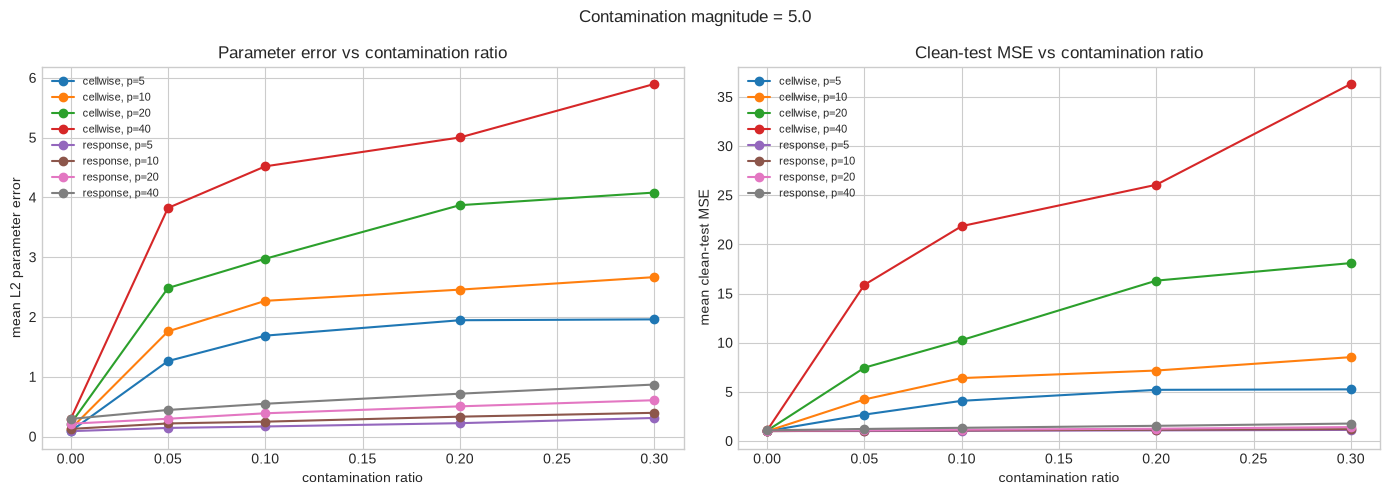

In [11]:
# Cell 9 — Produce tables and plots

benchmark_summary = (
    benchmark_results.groupby(
        ["p", "contamination_ratio", "contamination_magnitude", "contamination_type"], as_index=False
    )
    .agg(
        mean_clean_test_MSE=("clean_test_MSE", "mean"),
        std_clean_test_MSE=("clean_test_MSE", "std"),
        mean_parameter_L2_error=("parameter_L2_error", "mean"),
        std_parameter_L2_error=("parameter_L2_error", "std"),
    )
    .sort_values(["contamination_type", "p", "contamination_magnitude", "contamination_ratio"])
)

display(benchmark_summary)

# Plot the middle predefined magnitude; edit BENCHMARK_MAGNITUDES in cell 1 to change it.
plot_magnitude = BENCHMARK_MAGNITUDES[len(BENCHMARK_MAGNITUDES) // 2]
plot_data = benchmark_summary[benchmark_summary["contamination_magnitude"] == plot_magnitude]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for contamination_type, type_data in plot_data.groupby("contamination_type"):
    for p_value, p_data in type_data.groupby("p"):
        label = f"{contamination_type}, p={p_value}"
        axes[0].plot(p_data["contamination_ratio"], p_data["mean_parameter_L2_error"], marker="o", label=label)
        axes[1].plot(p_data["contamination_ratio"], p_data["mean_clean_test_MSE"], marker="o", label=label)

axes[0].set(title="Parameter error vs contamination ratio", xlabel="contamination ratio", ylabel="mean L2 parameter error")
axes[1].set(title="Clean-test MSE vs contamination ratio", xlabel="contamination ratio", ylabel="mean clean-test MSE")
for axis in axes:
    axis.legend(fontsize=8)
fig.suptitle(f"Contamination magnitude = {plot_magnitude}")
fig.tight_layout()
plt.show()
